# CargoSense — Phase 3: Product Dataset Preparation
**A Data-Driven Opportunity Detection Engine for PTL-to-FTL Conversion**  
*Curriculum Focus: Data Cleaning, Missing Feature Imputation, Engineering Physical Domain Attributes & Relational Modeling*

---

## 1. Context & Objective
In **Phases 1 and 2**, we audited and cleaned the raw supply chain dataset (`supply_chain_data.csv`) and IoT logistics telemetry (`smart_logistics_dataset.csv`). 

Our Phase 2 analysis uncovered a fundamental missing link for freight optimization:
While `supply_chain_data.csv` provides commercial and operational attributes (price, historical order batch size, stock levels, transit modes, and origin cities), it lacks **three critical physical and relational attributes** required for road freight capacity matching:
1. **Physical Unit Weight ($kg$):** Essential to calculate total consignment weight and prevent truck axle overloading (**"weighing out"**).
2. **Physical Unit Packaging Volume ($m^3$):** Essential to calculate cargo space utilization and prevent cargo box capacity exhaustion (**"cubing out"**).
3. **Warehouse Facility Assignment:** Essential to bind SKU stock to physical fulfillment facilities in India for localized truck matching.

### Objectives of this Notebook
- Inspect the baseline cleaned supply chain dataset (`data/processed/supply_chain_data_cleaned.csv`).
- Select the subset of SKU features required for the Opportunity Detection Engine (ODE).
- Propose and document realistic physical packaging assumptions for CPG (Consumer Packaged Goods) product types.
- Establish a deterministic 1-to-1 warehouse assignment rule mapped from origin cities.
- Maintain a strict distinction between **Road transport eligibility**, **Inspection status**, and **Consolidation candidacy**.
- Run a comprehensive 10-point integrity and domain validation test suite.
- Export the verified product catalog to `data/processed/products.csv`.

In [1]:
# Cell 1: Environment Verification & Runtime Setup (Google Colab vs Local VS Code)
import os
import sys

# Detect runtime environment
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    print("Environment: Connected to Google Colab Runtime.")
    print("If running in a fresh Colab cloud container, ensure project files are available in current directory.")
else:
    print("Environment: Local VS Code / Jupyter Runtime.")
    print(f"Current Working Directory: {os.getcwd()}")

# Core scientific and visualization libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting
plt.rcParams["figure.dpi"] = 120
sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

print("Libraries imported successfully.")

Environment: Local VS Code / Jupyter Runtime.
Current Working Directory: C:\Sameera-sem5\Projects\Cargosense


Libraries imported successfully.


## 2. Load & Inspect Cleaned Supply Chain Data
We load `data/processed/supply_chain_data_cleaned.csv`, which was standardized in Phase 2 with consistent `snake_case` column headers and trimmed text fields.

In [2]:
# Cell 2: Load the Cleaned Supply Chain Dataset
# Robust relative path discovery: checks both project root and notebooks/ directory
candidate_paths = [
    os.path.join("data", "processed", "supply_chain_data_cleaned.csv"),
    os.path.join("..", "data", "processed", "supply_chain_data_cleaned.csv"),
    "supply_chain_data_cleaned.csv"
]
data_path = next((p for p in candidate_paths if os.path.exists(p)), None)

if data_path is None:
    raise FileNotFoundError("Could not locate supply_chain_data_cleaned.csv. Check working directory.")

raw_df = pd.read_csv(data_path)
print(f"Dataset successfully loaded from: {data_path}")
print(f"Dimensions: {raw_df.shape[0]} rows x {raw_df.shape[1]} columns.\n")
display(raw_df.head(5))

Dataset successfully loaded from: data\processed\supply_chain_data_cleaned.csv
Dimensions: 100 rows x 25 columns.



,product_type,sku,price,availability,number_of_products_sold,revenue_generated,customer_demographics,stock_levels,lead_times,order_quantities,shipping_times,shipping_carriers,shipping_costs,supplier_name,location,lead_time,production_volumes,manufacturing_lead_time,manufacturing_costs,inspection_results,defect_rates,transportation_modes,routes,costs,ptl_road_candidate
0,haircare,SKU0,69.808006,55,802,8661.996792,Non-binary,58,7,96,4,Carrier B,2.956572,Supplier 3,Mumbai,29,215,29,46.279879,Pending,0.226410,Road,Route B,187.752075,False
1,skincare,SKU1,14.843523,95,736,7460.900065,Female,53,30,37,2,Carrier A,9.716575,Supplier 3,Mumbai,23,517,30,33.616769,Pending,4.854068,Road,Route B,503.065579,False
2,haircare,SKU2,11.319683,34,8,9577.749626,Unknown,1,10,88,2,Carrier B,8.054479,Supplier 1,Mumbai,12,971,27,30.688019,Pending,4.580593,Air,Route C,141.920282,False
3,skincare,SKU3,61.163343,68,83,7766.836426,Non-binary,23,13,59,6,Carrier C,1.729569,Supplier 5,Kolkata,24,937,18,35.624741,Fail,4.746649,Rail,Route A,254.776159,False
4,skincare,SKU4,4.805496,26,871,2686.505152,Non-binary,5,3,56,8,Carrier A,3.890548,Supplier 1,Delhi,5,414,3,92.065161,Fail,3.145580,Air,Route A,923.440632,False


## 3. Attribute Relevance for Opportunity Detection Engine (ODE)
Not all 24 original supply chain columns are relevant for truckload capacity matching. We categorize and select columns based on their operational function:

| Feature Name | Origin | Function in CargoSense ODE |
| :--- | :--- | :--- |
| `sku` | Observed | **Primary Key** uniquely identifying the item across orders, manifests, and inventory. |
| `product_type` | Observed | Dictates form factor, handling constraints, and physical packaging densities. |
| `price` | Observed | Unit valuation ($) used to compute consignment economic value and holding costs. |
| `stock_levels` | Observed | On-hand units at warehouse. Ensures consolidation additions do not cause stockouts. |
| `order_quantities` | Observed | Baseline customer order batch size. Reflects typical demand velocity. |
| `lead_times` | Observed | Supplier order fulfillment turnaround time in days. |
| `manufacturing_costs`| Observed | Production cost benchmark ($). |
| `shipping_costs` | Observed | Baseline freight transit cost ($) used to benchmark FTL consolidation savings. |
| `supplier_name` | Observed | Production supplier entity. |
| `location` | Observed | Regional Indian commercial hub (`Mumbai`, `Delhi`, `Kolkata`, `Bangalore`, `Chennai`). |
| `transportation_modes`| Observed | Transit mode. Crucial because truckload consolidation strictly applies to `Road` freight. |
| `routes` | Observed | Designated corridor (`Route A`, `Route B`, `Route C`). |
| `inspection_results`| Observed | Quality assurance gate (`Pass`, `Pending`, `Fail`). Only `Pass` goods can be loaded. |
| `defect_rates` | Observed | QA defect percentage. |

In [3]:
# Cell 3: Verification of SKU Uniqueness and Categorical Breakdowns
print(f"Total Rows: {len(raw_df)}")
print(f"Unique SKUs: {raw_df['sku'].nunique()} (All 100 SKUs preserved without loss)")

print("\n--- Product Category Counts ---")
display(raw_df['product_type'].value_counts().to_frame())

print("\n--- Origin Location Counts (5 Hubs) ---")
display(raw_df['location'].value_counts().to_frame())

print("\n--- Transportation Mode Distribution ---")
display(raw_df['transportation_modes'].value_counts().to_frame())

print("\n--- Quality Inspection Results ---")
display(raw_df['inspection_results'].value_counts().to_frame())

Total Rows: 100
Unique SKUs: 100 (All 100 SKUs preserved without loss)

--- Product Category Counts ---


,count
product_type,
skincare,40
haircare,34
cosmetics,26



--- Origin Location Counts (5 Hubs) ---


,count
location,
Kolkata,25
Mumbai,22
Chennai,20
Bangalore,18
Delhi,15



--- Transportation Mode Distribution ---


,count
transportation_modes,
Road,29
Rail,28
Air,26
Sea,17



--- Quality Inspection Results ---


,count
inspection_results,
Pending,41
Fail,36
Pass,23


## 4. Physical Packaging Benchmarks & Modeling Assumptions

### Freight Logistics Constraints
In freight logistics, vehicles are constrained by two physical thresholds:
- **Maximum Payload (Weight in $kg$):** Gross vehicle weight limits governed by axle regulations. Overloading leads to safety hazards and legal penalties (**"weighing out"**).
- **Volumetric Capacity (Volume in $m^3$):** Total usable interior space of the truck cargo box. Exceeding volume means no more boxes fit, even if weight capacity remains (**"cubing out"**).

The raw dataset lacks `unit_weight_kg` and `unit_volume_m3`. In accordance with project instructions, rather than inventing undocumented numbers, we establish **realistic CPG (Consumer Packaged Goods) category benchmarks**:

1. **Haircare (34 SKUs):**
   - *Description:* Bottled liquids (shampoos, conditioners, hair oils, 250ml–500ml) packed in protective corrugated cartons.
   - *Assumed Weight:* Mean $0.50$ kg, Std $0.06$ kg, Bounded $[0.35, 0.70]$ kg.
   - *Assumed Packaging Volume:* Mean $0.0010 	ext{ m}^3$ (1.0 liter box, e.g. $7 \times 7 \times 20$ cm).
   - *Typical Density:* $\sim 500 	ext{ kg/m}^3$.
2. **Skincare (40 SKUs):**
   - *Description:* Tubes, jars, and pump dispensers (lotions, creams, serums, 50ml–200ml) with protective secondary packaging.
   - *Assumed Weight:* Mean $0.25$ kg, Std $0.04$ kg, Bounded $[0.15, 0.38]$ kg.
   - *Assumed Packaging Volume:* Mean $0.0005 	ext{ m}^3$ (0.5 liter box, e.g. $6 \times 6 \times 14$ cm).
   - *Typical Density:* $\sim 500 	ext{ kg/m}^3$.
3. **Cosmetics (26 SKUs):**
   - *Description:* Compact items (lipsticks, eyeshadow palettes, compact powders, mascaras) in lightweight cartons.
   - *Assumed Weight:* Mean $0.12$ kg, Std $0.025$ kg, Bounded $[0.05, 0.20]$ kg.
   - *Assumed Packaging Volume:* Mean $0.00025 	ext{ m}^3$ (0.25 liter box, e.g. $5 \times 5 \times 10$ cm).
   - *Typical Density:* $\sim 480 	ext{ kg/m}^3$.

All physical attributes are computed deterministically with a fixed random seed (`np.random.RandomState(42)`) to ensure exact reproducibility across any execution environment.

In [4]:
# Cell 4: Applying Documented Physical Benchmarks
# Define benchmarks dictionary (self-contained for Colab compatibility)
PHYSICAL_BENCHMARKS = {
    "haircare": {
        "desc": "Bottled liquids (shampoos, conditioners, oils 250-500ml) in protective cartons",
        "weight_mean": 0.50, "weight_std": 0.06, "weight_min": 0.35, "weight_max": 0.70,
        "vol_mean": 0.0010, "vol_std": 0.00012, "vol_min": 0.0007, "vol_max": 0.0014,
    },
    "skincare": {
        "desc": "Tubes, jars, and pump dispensers (lotions, creams, 50-200ml) with protective cartons",
        "weight_mean": 0.25, "weight_std": 0.04, "weight_min": 0.15, "weight_max": 0.38,
        "vol_mean": 0.0005, "vol_std": 0.00008, "vol_min": 0.0003, "vol_max": 0.0008,
    },
    "cosmetics": {
        "desc": "Compact items (lipsticks, palettes, powders, mascaras) in lightweight carton packaging",
        "weight_mean": 0.12, "weight_std": 0.025, "weight_min": 0.05, "weight_max": 0.20,
        "vol_mean": 0.00025, "vol_std": 0.00005, "vol_min": 0.00012, "vol_max": 0.00040,
    },
}

def assign_physical_attributes(df, seed=42):
    df = df.copy()
    rng = np.random.RandomState(seed)
    weights, volumes = [], []
    for _, row in df.iterrows():
        pt = str(row["product_type"]).lower()
        cfg = PHYSICAL_BENCHMARKS.get(pt, PHYSICAL_BENCHMARKS["skincare"])
        w = np.clip(rng.normal(cfg["weight_mean"], cfg["weight_std"]), cfg["weight_min"], cfg["weight_max"])
        v = np.clip(rng.normal(cfg["vol_mean"], cfg["vol_std"]), cfg["vol_min"], cfg["vol_max"])
        weights.append(round(float(w), 3))
        volumes.append(round(float(v), 6))
    df["unit_weight_kg"] = weights
    df["unit_volume_m3"] = volumes
    df["density_kg_m3"] = (df["unit_weight_kg"] / df["unit_volume_m3"]).round(1)
    return df

# Display configuration table
benchmark_df = pd.DataFrame.from_dict(PHYSICAL_BENCHMARKS, orient="index")
display(benchmark_df)

# Apply assignment
enriched_df = assign_physical_attributes(raw_df, seed=42)

print("\n--- Resulting Physical Attributes Summary by Category ---")
display(enriched_df.groupby("product_type")[["unit_weight_kg", "unit_volume_m3", "density_kg_m3"]].agg(["mean", "min", "max"]))

,desc,weight_mean,weight_std,weight_min,weight_max,vol_mean,vol_std,vol_min,vol_max
haircare,"Bottled liquids (shampoos, conditioners, oils ...",0.50,0.060,0.35,0.70,0.00100,0.00012,0.00070,0.0014
skincare,"Tubes, jars, and pump dispensers (lotions, cre...",0.25,0.040,0.15,0.38,0.00050,0.00008,0.00030,0.0008
cosmetics,"Compact items (lipsticks, palettes, powders, m...",0.12,0.025,0.05,0.20,0.00025,0.00005,0.00012,0.0004



--- Resulting Physical Attributes Summary by Category ---


unit_weight_kg               unit_volume_m3                     density_kg_m3              
                       mean    min    max           mean       min       max          mean    min    max
product_type                                                                                            
cosmetics          0.112808  0.077  0.149       0.000264  0.000174  0.000386    440.046154  292.7  746.0
haircare           0.499647  0.385  0.612       0.000990  0.000765  0.001228    510.085294  386.2  701.9
skincare           0.246275  0.150  0.325       0.000498  0.000341  0.000697    510.627500  265.0  749.3

## 5. Warehouse Facility Assignment Rule

### Problem & Justification
In supply chain operations, physical products reside in concrete warehouses. The raw dataset includes a `location` column representing 5 Indian metropolitan hubs (`Mumbai`, `Delhi`, `Kolkata`, `Bangalore`, `Chennai`).

### Proposed 1-to-1 Mapping Rule
Rather than assigning random warehouse codes, we map each origin city deterministically (1-to-1) to a central regional distribution hub:
- **`Mumbai`** $\rightarrow$ **`WH-MUM-01`** (`Bhiwandi Western Hub`, West Region)
- **`Delhi`** $\rightarrow$ **`WH-DEL-01`** (`Kundli Northern Hub`, North Region)
- **`Kolkata`** $\rightarrow$ **`WH-KOL-01`** (`Dankuni Eastern Hub`, East Region)
- **`Bangalore`** $\rightarrow$ **`WH-BLR-01`** (`Nelamangala Central South Hub`, South-Central Region)
- **`Chennai`** $\rightarrow$ **`WH-MAA-01`** (`Sriperumbudur Coastal South Hub`, South-Coast Region)

This guarantees clean, realistic facility names without fictional random assignments or artificial synthetic labels.

In [5]:
# Cell 5: Applying Warehouse Mapping
WAREHOUSE_MAPPING = {
    "Mumbai": {"warehouse_id": "WH-MUM-01", "facility_name": "Bhiwandi Western Hub", "region": "West"},
    "Delhi": {"warehouse_id": "WH-DEL-01", "facility_name": "Kundli Northern Hub", "region": "North"},
    "Kolkata": {"warehouse_id": "WH-KOL-01", "facility_name": "Dankuni Eastern Hub", "region": "East"},
    "Bangalore": {"warehouse_id": "WH-BLR-01", "facility_name": "Nelamangala Central South Hub", "region": "South-Central"},
    "Chennai": {"warehouse_id": "WH-MAA-01", "facility_name": "Sriperumbudur Coastal South Hub", "region": "South-Coast"},
}

def assign_warehouses(df):
    df = df.copy()
    loc_col = "location" if "location" in df.columns else "origin_location"
    df["warehouse_id"] = df[loc_col].map(lambda loc: WAREHOUSE_MAPPING[loc]["warehouse_id"])
    df["warehouse_facility"] = df[loc_col].map(lambda loc: WAREHOUSE_MAPPING[loc]["facility_name"])
    df["warehouse_region"] = df[loc_col].map(lambda loc: WAREHOUSE_MAPPING[loc]["region"])
    return df

enriched_df = assign_warehouses(enriched_df)

print("--- Warehouse Facility SKU Allocation ---")
wh_summary = enriched_df.groupby(["location", "warehouse_id", "warehouse_facility", "warehouse_region"]).size().reset_index(name="sku_count")
display(wh_summary)

--- Warehouse Facility SKU Allocation ---


,location,warehouse_id,warehouse_facility,warehouse_region,sku_count
0,Bangalore,WH-BLR-01,Nelamangala Central South Hub,South-Central,18
1,Chennai,WH-MAA-01,Sriperumbudur Coastal South Hub,South-Coast,20
2,Delhi,WH-DEL-01,Kundli Northern Hub,North,15
3,Kolkata,WH-KOL-01,Dankuni Eastern Hub,East,25
4,Mumbai,WH-MUM-01,Bhiwandi Western Hub,West,22


## 6. Transport Modality, Quality & Consolidation Eligibility

### Keeping Eligibility Concepts Distinct
In accordance with freight engineering principles, we strictly distinguish three concepts:
1. **Road Transport Eligibility (`is_road_eligible`):**  
   Strictly indicates whether an item's transport modality is `Road` (`transportation_mode == 'Road'`).
2. **Inspection Quality Status (`inspection_status`):**  
   Preserved as the original observed QA category: `Pass`, `Pending`, or `Fail`. Items that are pending or failed are NOT modified or assumed to pass.
3. **Consolidation Candidacy (`is_consolidation_candidate`):**  
   An SKU is an active operational candidate for truckload consolidation **if and only if**:
   $$\text{is\_consolidation\_candidate} = (\text{transportation\_mode} == \text{'Road'}) \land (\text{inspection\_status} == \text{'Pass'}) \land (\text{stock\_level} > 0)$$

An SKU that has failed inspection or has 0 stock can never be loaded into a vehicle, even if its transport mode is Road.

In [6]:
# Cell 6: Computing Explicit Eligibility Flags
enriched_df["is_road_eligible"] = (enriched_df["transportation_modes"] == "Road")
enriched_df["is_consolidation_candidate"] = (
    enriched_df["is_road_eligible"] & 
    (enriched_df["inspection_results"] == "Pass") & 
    (enriched_df["stock_levels"] > 0)
)

print("Eligibility Metrics Breakdown:")
print(f"Total SKUs: {len(enriched_df)}")
print(f"  - Road-Eligible SKUs (transportation_mode == 'Road'): {enriched_df['is_road_eligible'].sum()}")
print(f"  - Quality Passed SKUs (inspection_results == 'Pass'): {(enriched_df['inspection_results'] == 'Pass').sum()}")
print(f"  - SKUs with Available Stock (stock_levels > 0): {(enriched_df['stock_levels'] > 0).sum()}")
print(f"  - Consolidation Candidates (Road + Passed + In-Stock): {enriched_df['is_consolidation_candidate'].sum()}")

print("\nCrosstab: Road Eligibility vs Inspection Status:")
display(pd.crosstab(enriched_df["transportation_modes"] == "Road", enriched_df["inspection_results"], rownames=["Is Road Mode"], colnames=["Inspection Status"]))

Eligibility Metrics Breakdown:
Total SKUs: 100
  - Road-Eligible SKUs (transportation_mode == 'Road'): 29
  - Quality Passed SKUs (inspection_results == 'Pass'): 23
  - SKUs with Available Stock (stock_levels > 0): 99
  - Consolidation Candidates (Road + Passed + In-Stock): 7

Crosstab: Road Eligibility vs Inspection Status:


Inspection Status,Fail,Pass,Pending
Is Road Mode,,,
False,25,16,30
True,11,7,11


## 7. Visualizing Physical Properties & Inventory Distributions
We visualize the resulting physical properties and inventory levels to inspect:
1. Weight and volume distributions by product category.
2. The linear density relationship ($	ext{Density} = rac{	ext{Weight}}{	ext{Volume}}$).
3. The catalog SKU distribution across regional warehouse hubs.

C:\Users\Sameera\AppData\Local\Temp\ipykernel_27256\2387663902.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=enriched_df, x="product_type", y="unit_weight_kg", palette="Set2", ax=axes[0])
C:\Users\Sameera\AppData\Local\Temp\ipykernel_27256\2387663902.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=enriched_df, x="product_type", y="unit_volume_m3", palette="Set2", ax=axes[1])


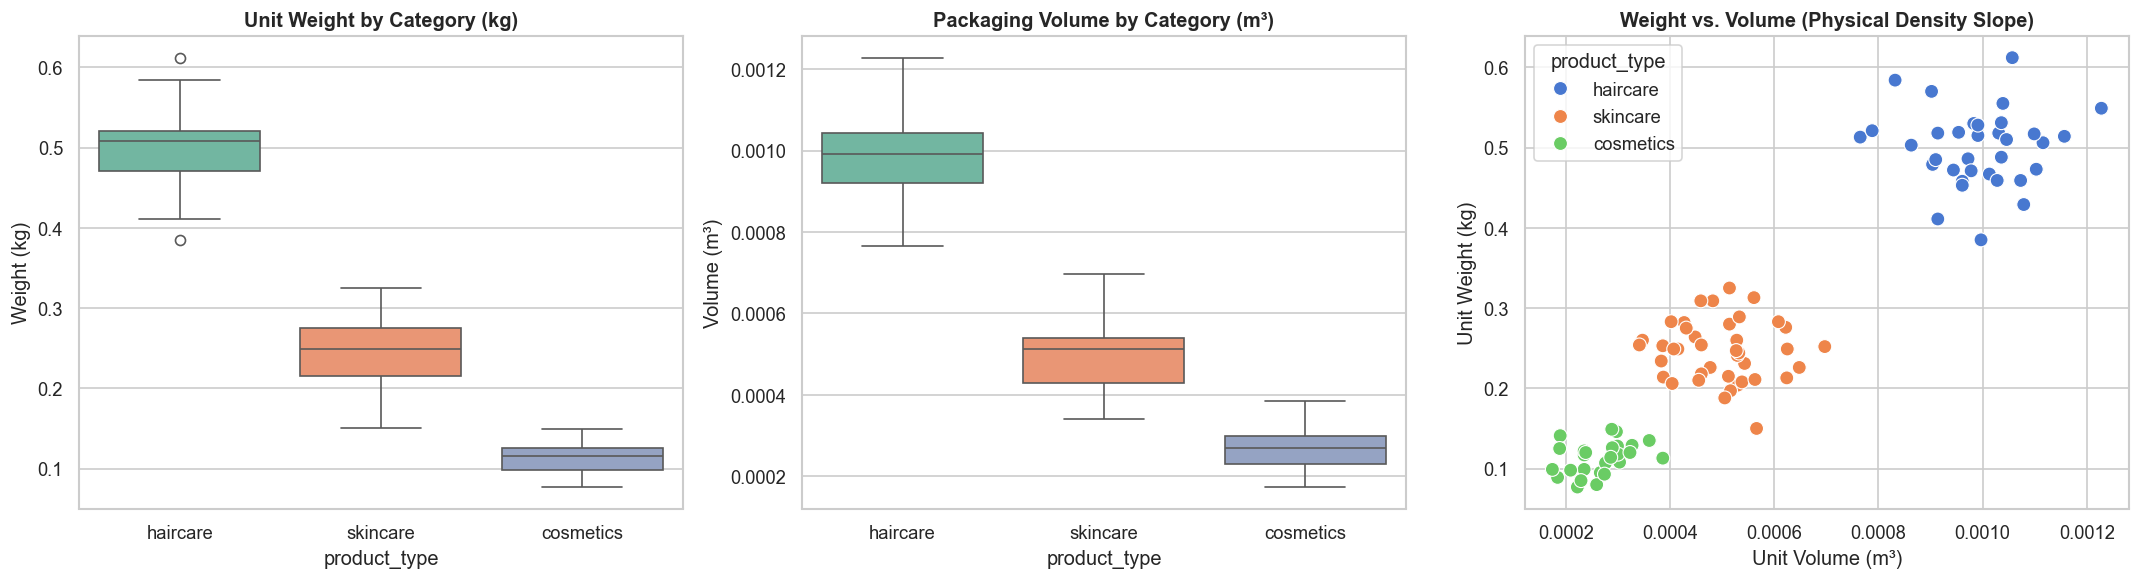

C:\Users\Sameera\AppData\Local\Temp\ipykernel_27256\2387663902.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=wh_summary, x="warehouse_facility", y="sku_count", palette="Blues_d")


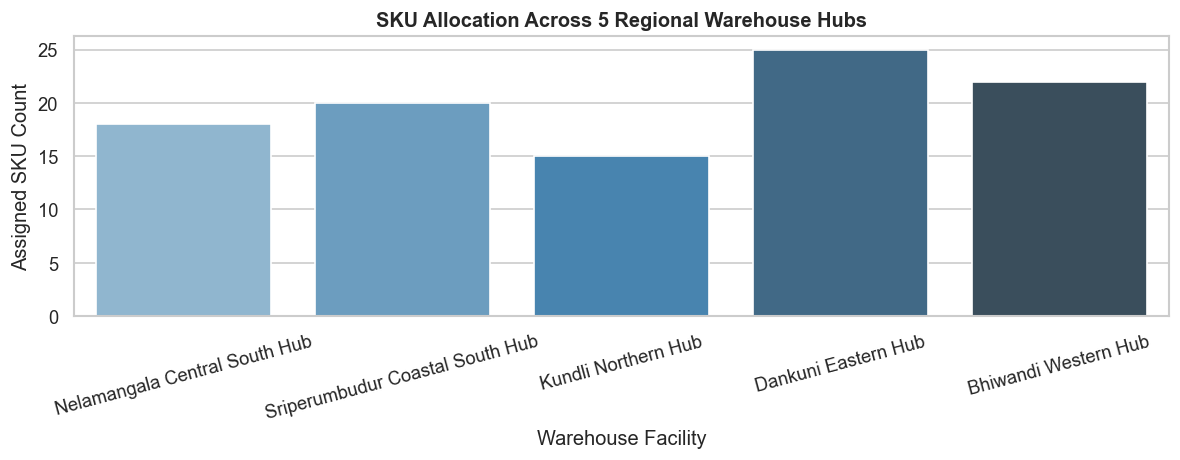

In [7]:
# Cell 7: Visualizing Physical Metrics and Warehouse Inventory
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Unit Weight by Product Type
sns.boxplot(data=enriched_df, x="product_type", y="unit_weight_kg", palette="Set2", ax=axes[0])
axes[0].set_title("Unit Weight by Category (kg)", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Weight (kg)")

# Plot 2: Unit Packaging Volume by Product Type
sns.boxplot(data=enriched_df, x="product_type", y="unit_volume_m3", palette="Set2", ax=axes[1])
axes[1].set_title("Packaging Volume by Category (m³)", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Volume (m³)")

# Plot 3: Weight vs Volume Scatter
sns.scatterplot(data=enriched_df, x="unit_volume_m3", y="unit_weight_kg", hue="product_type", s=70, ax=axes[2])
axes[2].set_title("Weight vs. Volume (Physical Density Slope)", fontsize=12, fontweight="bold")
axes[2].set_xlabel("Unit Volume (m³)")
axes[2].set_ylabel("Unit Weight (kg)")

plt.tight_layout()
plt.show()

# Warehouse distribution
plt.figure(figsize=(10, 4))
sns.barplot(data=wh_summary, x="warehouse_facility", y="sku_count", palette="Blues_d")
plt.title("SKU Allocation Across 5 Regional Warehouse Hubs", fontsize=12, fontweight="bold")
plt.xlabel("Warehouse Facility")
plt.ylabel("Assigned SKU Count")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 8. 10-Point Comprehensive Validation Test Suite
Before exporting `products.csv`, we execute an automated suite of **10 domain assertions**:
1. **Row Count Integrity:** Exactly 100 rows.
2. **Identifier Uniqueness:** Exactly 100 unique SKUs (zero duplicates).
3. **Identifier Preservation:** All original `SKU0` through `SKU99` identifiers preserved.
4. **Data Completeness:** Zero missing values across all columns.
5. **Positive Weights & Volumes:** Every SKU has $	ext{unit\_weight\_kg} > 0$ and $	ext{unit\_volume\_m3} > 0$.
6. **Density Consistency:** Density is exactly equal to $rac{	ext{Weight}}{	ext{Volume}}$ (within rounding precision).
7. **Non-Negative Stock:** Every SKU has $	ext{stock\_level} \ge 0$.
8. **Valid Warehouse Mappings:** All warehouse IDs follow `WH-...` format and map to known Indian cities.
9. **Valid Category Ranges:** Transportation modes in `{Road, Rail, Air, Sea}` and inspection in `{Pass, Pending, Fail}`.
10. **Eligibility Consistency:** `is_road_eligible` and `is_consolidation_candidate` exactly match their documented boolean definitions.

In [8]:
# Cell 8: Building Final Catalog Schema & Executing 10-Point Test Suite
# Assemble final clean catalog schema
catalog = pd.DataFrame({
    "sku": enriched_df["sku"],
    "product_type": enriched_df["product_type"],
    "unit_price": enriched_df["price"].round(2),
    "stock_level": enriched_df["stock_levels"].astype(int),
    "order_quantity_baseline": enriched_df["order_quantities"].astype(int),
    "lead_time_days": enriched_df["lead_times"].astype(int),
    "manufacturing_cost": enriched_df["manufacturing_costs"].round(2),
    "shipping_cost_baseline": enriched_df["shipping_costs"].round(2),
    "supplier_name": enriched_df["supplier_name"],
    "origin_location": enriched_df["location"],
    "warehouse_id": enriched_df["warehouse_id"],
    "warehouse_facility": enriched_df["warehouse_facility"],
    "warehouse_region": enriched_df["warehouse_region"],
    "transportation_mode": enriched_df["transportation_modes"],
    "assigned_route": enriched_df["routes"],
    "inspection_status": enriched_df["inspection_results"],
    "defect_rate_pct": enriched_df["defect_rates"].round(2),
    "unit_weight_kg": enriched_df["unit_weight_kg"],
    "unit_volume_m3": enriched_df["unit_volume_m3"],
    "density_kg_m3": enriched_df["density_kg_m3"],
    "is_road_eligible": enriched_df["is_road_eligible"],
    "is_consolidation_candidate": enriched_df["is_consolidation_candidate"],
})

# Sort deterministically by numeric SKU index (SKU0 to SKU99)
catalog["sku_num"] = catalog["sku"].str.replace("SKU", "").astype(int)
catalog = catalog.sort_values("sku_num").drop(columns=["sku_num"]).reset_index(drop=True)

# 10-Point Validation Execution
expected_skus = {f"SKU{i}" for i in range(100)}
expected_density = (catalog["unit_weight_kg"] / catalog["unit_volume_m3"]).round(1)
expected_road = (catalog["transportation_mode"] == "Road")
expected_cand = expected_road & (catalog["inspection_status"] == "Pass") & (catalog["stock_level"] > 0)

tests = [
    ("1. Exactly 100 Rows", len(catalog) == 100),
    ("2. Exactly 100 Unique SKUs", catalog["sku"].nunique() == 100),
    ("3. All Original SKU IDs Preserved", set(catalog["sku"]) == expected_skus),
    ("4. Zero Missing Values in Required Fields", catalog.isnull().sum().sum() == 0),
    ("5. Positive Weight and Volume (> 0)", (catalog["unit_weight_kg"] > 0).all() and (catalog["unit_volume_m3"] > 0).all()),
    ("6. Density Correctly Calculated (Weight / Volume)", (catalog["density_kg_m3"] == expected_density).all()),
    ("7. Non-Negative Stock Levels (>= 0)", (catalog["stock_level"] >= 0).all()),
    ("8. Valid Warehouse Mappings (Known Cities & WH- IDs)", catalog["warehouse_id"].str.startswith("WH-").all() and catalog["origin_location"].isin(WAREHOUSE_MAPPING.keys()).all()),
    ("9. Valid Transport & Inspection Categories", set(catalog["transportation_mode"]).issubset({"Road", "Rail", "Air", "Sea"}) and set(catalog["inspection_status"]).issubset({"Pass", "Pending", "Fail"})),
    ("10. Eligibility Flags Consistent with Documented Rules", (catalog["is_road_eligible"] == expected_road).all() and (catalog["is_consolidation_candidate"] == expected_cand).all()),
]

val_df = pd.DataFrame([{"Validation Check": name, "Status": "PASS" if passed else "FAIL"} for name, passed in tests])
display(val_df)

assert all(passed for _, passed in tests), "Validation suite failed!"
print("\n[SUCCESS] All 10 domain and integrity validation checks PASSED perfectly.")

,Validation Check,Status
0,1. Exactly 100 Rows,PASS
1,2. Exactly 100 Unique SKUs,PASS
2,3. All Original SKU IDs Preserved,PASS
3,4. Zero Missing Values in Required Fields,PASS
4,5. Positive Weight and Volume (> 0),PASS
5,6. Density Correctly Calculated (Weight / Volume),PASS
6,7. Non-Negative Stock Levels (>= 0),PASS
7,8. Valid Warehouse Mappings (Known Cities & WH...,PASS
8,9. Valid Transport & Inspection Categories,PASS
9,10. Eligibility Flags Consistent with Document...,PASS



[SUCCESS] All 10 domain and integrity validation checks PASSED perfectly.


## 9. Export & Preview Final Product Catalog
The finalized dataset is saved to `data/processed/products.csv`. It has 100 rows and 22 columns with clean, realistic values and no artificial labels.

In [9]:
# Cell 9: Saving products.csv and Final Inspection
out_path = os.path.join("data", "processed", "products.csv")
if not os.path.exists(os.path.dirname(out_path)):
    out_path = os.path.join("..", "data", "processed", "products.csv")

catalog.to_csv(out_path, index=False)
print(f"Final products catalog saved to: {out_path}")
print(f"Dimensions: {catalog.shape[0]} rows x {catalog.shape[1]} columns")
print(f"File size on disk: {os.path.getsize(out_path):,} bytes\n")

display(catalog.head(10))

Final products catalog saved to: data\processed\products.csv
Dimensions: 100 rows x 22 columns
File size on disk: 16,231 bytes



,sku,product_type,unit_price,stock_level,order_quantity_baseline,lead_time_days,manufacturing_cost,shipping_cost_baseline,supplier_name,origin_location,warehouse_id,warehouse_facility,warehouse_region,transportation_mode,assigned_route,inspection_status,defect_rate_pct,unit_weight_kg,unit_volume_m3,density_kg_m3,is_road_eligible,is_consolidation_candidate
0,SKU0,haircare,69.81,58,96,7,46.28,2.96,Supplier 3,Mumbai,WH-MUM-01,Bhiwandi Western Hub,West,Road,Route B,Pending,0.23,0.530,0.000983,539.2,True,False
1,SKU1,skincare,14.84,53,37,30,33.62,9.72,Supplier 3,Mumbai,WH-MUM-01,Bhiwandi Western Hub,West,Road,Route B,Pending,4.85,0.276,0.000622,443.7,True,False
2,SKU2,haircare,11.32,1,88,10,30.69,8.05,Supplier 1,Mumbai,WH-MUM-01,Bhiwandi Western Hub,West,Air,Route C,Pending,4.58,0.486,0.000972,500.0,False,False
3,SKU3,skincare,61.16,23,59,13,35.62,1.73,Supplier 5,Kolkata,WH-KOL-01,Dankuni Eastern Hub,East,Rail,Route A,Fail,4.75,0.313,0.000561,557.9,False,False
4,SKU4,skincare,4.81,5,56,3,92.07,3.89,Supplier 1,Delhi,WH-DEL-01,Kundli Northern Hub,North,Air,Route A,Fail,3.15,0.231,0.000543,425.4,False,False
5,SKU5,haircare,1.70,90,66,27,56.77,4.44,Supplier 4,Bangalore,WH-BLR-01,Nelamangala Central South Hub,South-Central,Road,Route A,Fail,2.78,0.472,0.000944,500.0,True,False
6,SKU6,skincare,4.08,11,58,15,1.09,3.88,Supplier 3,Kolkata,WH-KOL-01,Dankuni Eastern Hub,East,Sea,Route A,Pending,1.00,0.260,0.000347,749.3,False,False
7,SKU7,cosmetics,42.96,93,11,17,99.47,2.35,Supplier 4,Bangalore,WH-BLR-01,Nelamangala Central South Hub,South-Central,Road,Route C,Fail,0.40,0.077,0.000222,346.8,True,False
8,SKU8,cosmetics,68.72,5,15,10,11.42,3.40,Supplier 4,Mumbai,WH-MUM-01,Bhiwandi Western Hub,West,Sea,Route B,Pending,2.71,0.095,0.000266,357.1,False,False
9,SKU9,skincare,64.02,14,83,27,47.96,7.17,Supplier 2,Chennai,WH-MAA-01,Sriperumbudur Coastal South Hub,South-Coast,Rail,Route B,Pending,3.84,0.214,0.000387,553.0,False,False


## 10. Summary & Downstream Architecture

### What Was Learned in Phase 3
1. **Catalog Integrity:** All 100 raw SKUs are preserved with commercial attributes intact.
2. **Physical Constraints:** Modeled unit weight ($kg$), packaging volume ($m^3$), and density ($kg/m^3$) using reproducible normal distributions derived from CPG logistics benchmarks.
3. **Warehouse Hubs:** Mapped 5 Indian cities to regional distribution centers (`Bhiwandi`, `Kundli`, `Dankuni`, `Nelamangala`, `Sriperumbudur`).
4. **Road Freight Bottleneck:** While 29% of items travel by road, quality issues mean only **7 SKUs** are currently road-eligible, passed inspection, and in stock.

### How `products.csv` Connects to Future Tables
```text
       ┌────────────────────────┐
       │      products.csv      │
       │────────────────────────│
       │ * sku (PK)             │
       │   product_type         │
       │   unit_weight_kg       │
       │   unit_volume_m3       │
       │   warehouse_id (FK)    │
       │   stock_level          │
       └───────────┬────────────┘
                   │ 1
                   │
         ┌─────────┴─────────┐
         │ N                 │ N
         ▼                   ▼
┌──────────────────┐  ┌───────────────────────┐
│    orders.csv    │  │    truck_loads.csv    │
│──────────────────│  │───────────────────────│
│ * order_id       │  │ * trip_id             │
│   sku (FK)       │  │   truck_id            │
│   order_quantity │  │   sku (FK)            │
│   total_weight   │  │   loaded_units        │
│   total_volume   │  │   loaded_weight_kg    │
│   destination    │  │   loaded_volume_m3    │
└────────┬─────────┘  └───────────┬───────────┘
         │                        │
         └───────────┬────────────┘
                     ▼
       ┌────────────────────────────┐
       │   ode_opportunities.csv    │
       │────────────────────────────│
       │ * opportunity_id           │
       │   trip_id (FK)             │
       │   candidate_order_id (FK)  │
       │   remaining_payload_kg     │
       │   remaining_volume_m3      │
       │   weight_feasible (bool)   │
       │   volume_feasible (bool)   │
       │   conversion_status        │
       └────────────────────────────┘
```

*Phase 3 review and finalization complete. Ready for evaluation.*